**Desenvolvimento de IA para Análise Preditiva [T3]**

Situação de Aprendizagem (Projeto Avaliativo) - Módulo 1 - Semana 14

Aluno: Igor de Verçosa Mello


In [28]:
# COnfiguração do ambiente
# Fazer o uploud do arquivo "manutenção_preditiva.csv"
# Importa as bibliotecas e fixa uma semente (SEED) para que os resultados sejam reprodutíveis: quem rodar o notebook obtém os mesmos números.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from imblearn.over_sampling import SMOTENC

SEED = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

df = pd.read_csv("manutencao_preditiva.csv")
df.head()

,udi,id_produto,tipo,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina,falha_twf,falha_hdf,falha_pwf,falha_osf,falha_rnf
0,1,M14860,M,298.1,308.6,1551.0,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408.0,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498.0,49.4,5,0,0,0,0,0,0
3,4,L47183,L,NaN,NaN,NaN,NaN,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408.0,40.0,9,0,0,0,0,0,0


Fase 1 — Análise Exploratória de Dados (EDA)

In [29]:
# Dimensões, tipos e valores ausentes
print(f"Linhas: {df.shape[0]} | Colunas: {df.shape[1]}\n")
print("Tipos de dados:")
print(df.dtypes, "\n")
print("Valores ausentes por coluna:")
print(df.isna().sum())

Linhas: 10000 | Colunas: 14

Tipos de dados:
udi                          int64
id_produto                  object
tipo                        object
temperatura_ar_k           float64
temperatura_processo_k     float64
velocidade_rotacao_rpm     float64
torque_nm                  float64
desgaste_ferramenta_min      int64
falha_maquina                int64
falha_twf                    int64
falha_hdf                    int64
falha_pwf                    int64
falha_osf                    int64
falha_rnf                    int64
dtype: object 

Valores ausentes por coluna:
udi                          0
id_produto                   0
tipo                         0
temperatura_ar_k           500
temperatura_processo_k     500
velocidade_rotacao_rpm     500
torque_nm                  500
desgaste_ferramenta_min      0
falha_maquina                0
falha_twf                    0
falha_hdf                    0
falha_pwf                    0
falha_osf                    0
falha_rnf        

In [30]:
# Listas de colunas usadas ao longo do projeto
COLS_NUM = ["temperatura_ar_k", "temperatura_processo_k",
            "velocidade_rotacao_rpm", "torque_nm", "desgaste_ferramenta_min"]
COLS_MODOS_FALHA = ["falha_twf", "falha_hdf", "falha_pwf", "falha_osf", "falha_rnf"]

# Resumo estatístico das colunas numéricas (exigência: .describe())
df.describe().T

,count,mean,std,min,25%,50%,75%,max
udi,10000.0,5000.500000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
temperatura_ar_k,9500.0,300.002158,2.001689,295.3,298.30,300.1,301.50,304.5
temperatura_processo_k,9500.0,310.000895,1.486432,305.7,308.80,310.1,311.10,313.8
velocidade_rotacao_rpm,9500.0,1539.245263,180.273589,1168.0,1423.00,1504.0,1613.00,2886.0
torque_nm,9500.0,39.974168,9.995453,3.8,33.10,40.1,46.70,76.6
desgaste_ferramenta_min,10000.0,107.951000,63.654147,0.0,53.00,108.0,162.00,253.0
falha_maquina,10000.0,0.033900,0.180981,0.0,0.00,0.0,0.00,1.0
falha_twf,10000.0,0.004600,0.067671,0.0,0.00,0.0,0.00,1.0
falha_hdf,10000.0,0.011500,0.106625,0.0,0.00,0.0,0.00,1.0
falha_pwf,10000.0,0.009500,0.097009,0.0,0.00,0.0,0.00,1.0


Gráfico 1 — Distribuição das variáveis preditoras

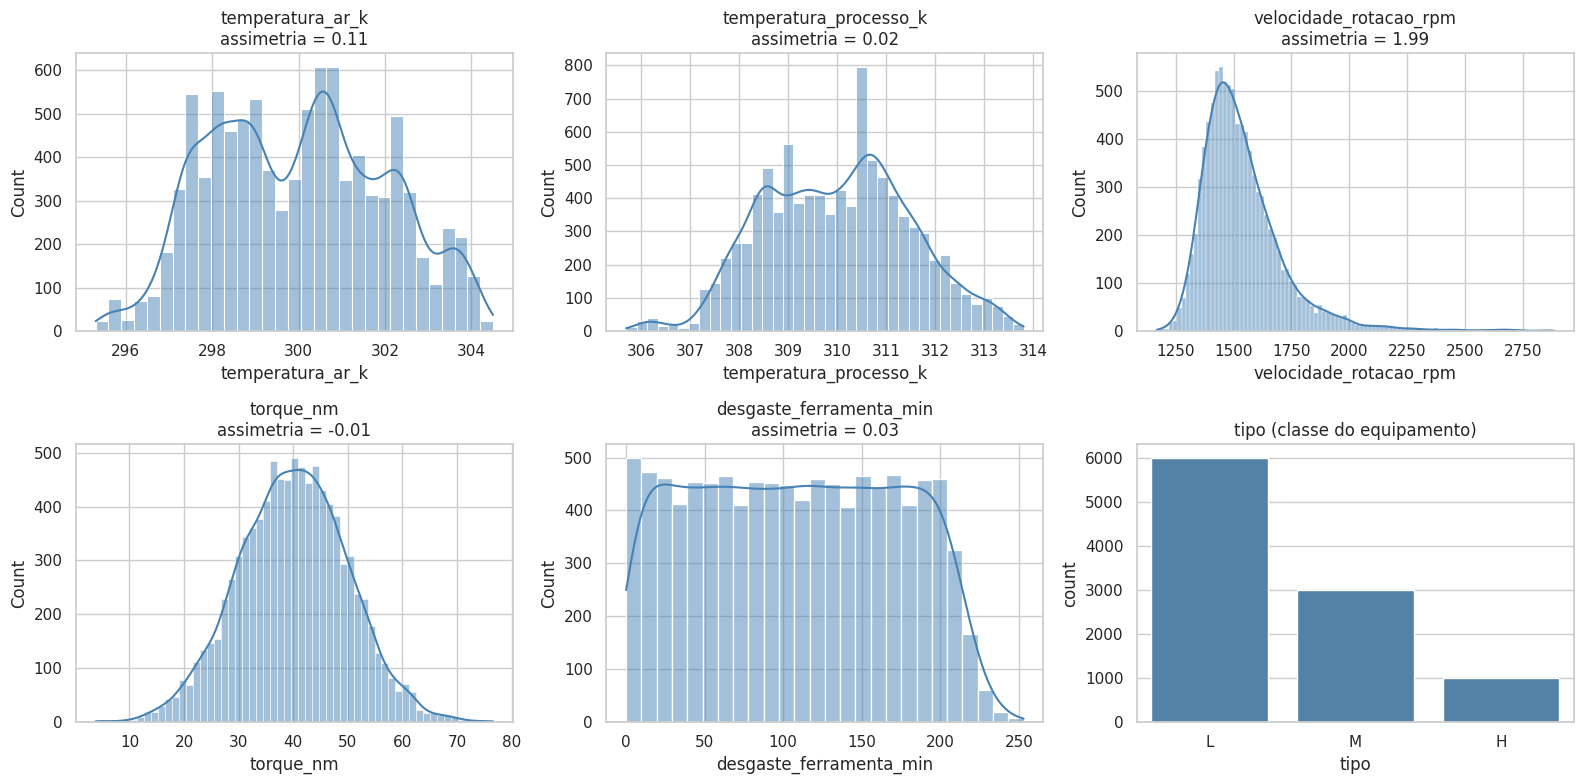

In [31]:
# Histogramas com curva de densidade (KDE) mostram o formato de cada variável: simétrica ou assimétrica. Isso será usado na escolha entre média e mediana (Fase 2).
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.ravel()
for ax, col in zip(axes, COLS_NUM):
    sns.histplot(df[col], kde=True, ax=ax, color="steelblue")
    ax.set_title(f"{col}\nassimetria = {df[col].skew():.2f}")
sns.countplot(data=df, x="tipo", order=["L", "M", "H"], ax=axes[5], color="steelblue")
axes[5].set_title("tipo (classe do equipamento)")
plt.tight_layout()
plt.show()

Gráfico 2 — Desbalanceamento da variável alvo

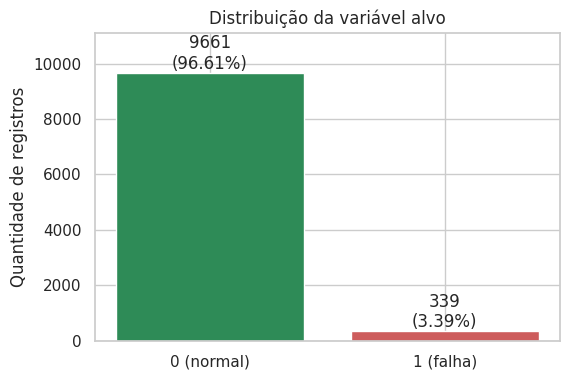

Acurácia de quem sempre prevê 0: 96.61%


In [32]:
contagem = df["falha_maquina"].value_counts().sort_index()
pct = df["falha_maquina"].value_counts(normalize=True).sort_index() * 100

fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar(["0 (normal)", "1 (falha)"], contagem.values, color=["seagreen", "indianred"])
for b, n, p in zip(barras, contagem.values, pct.values):
    ax.text(b.get_x() + b.get_width()/2, b.get_height(), f"{n}\n({p:.2f}%)", ha="center", va="bottom")
ax.set_ylim(0, contagem.max() * 1.15)
ax.set_title("Distribuição da variável alvo")
ax.set_ylabel("Quantidade de registros")
plt.show()

# Acurácia de um 'modelo' que SEMPRE responde "sem falha" (referência mínima)
print(f"Acurácia de quem sempre prevê 0: {pct[0]:.2f}%")

Gráfico 3 — Mapa de calor da correlação de Pearson

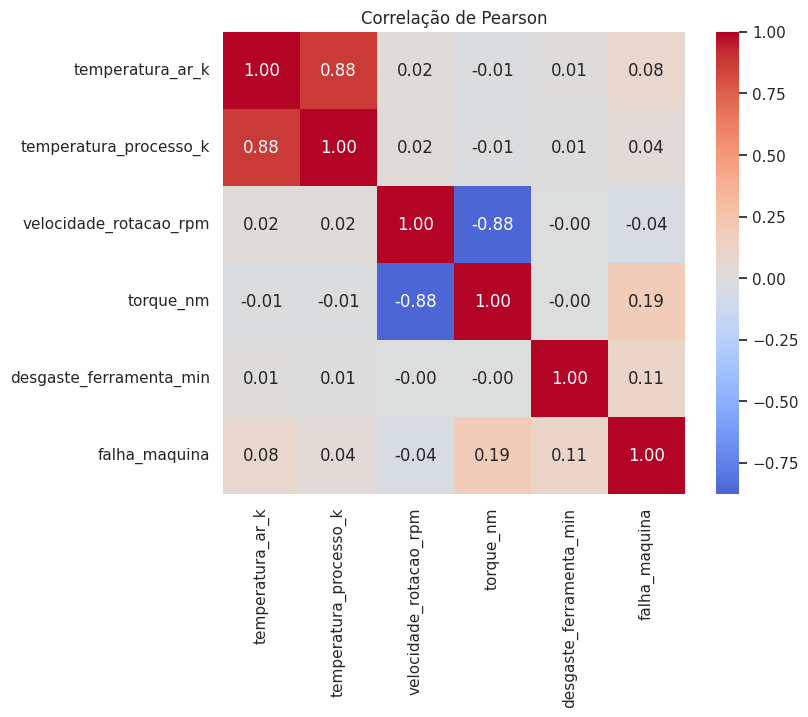

In [33]:
corr = df[COLS_NUM + ["falha_maquina"]].corr(method="pearson")
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlação de Pearson")
plt.show()

Gráfico 4 — Perfil das máquinas que falham

Média das variáveis por classe do alvo:


,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min
falha_maquina,,,,,
0,299.97,309.99,1540.62,39.62,106.69
1,300.89,310.30,1499.99,50.05,143.78



Taxa de falha (%) por tipo:


,falha_maquina
tipo,
L,3.92
M,2.77
H,2.09


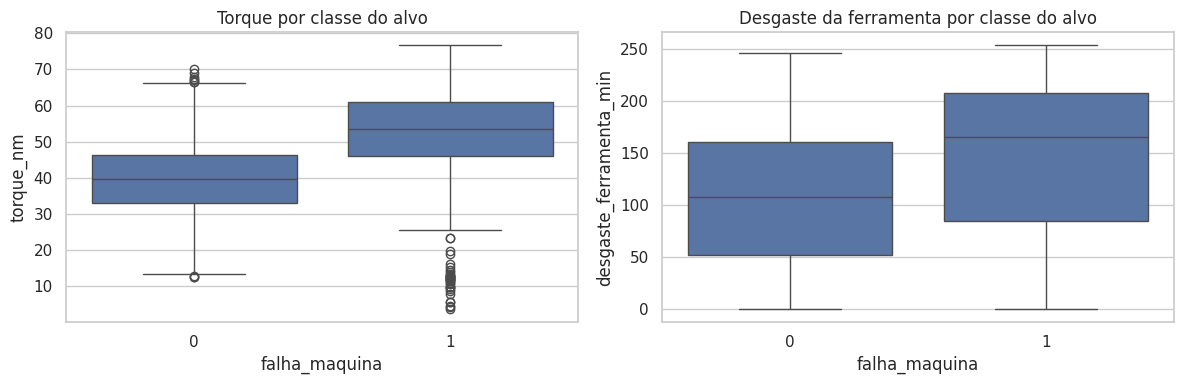

In [34]:
# Comparar médias por classe e taxa de falha por tipo ajuda a ver quais variáveis separam os grupos.
print("Média das variáveis por classe do alvo:")
display(df.groupby("falha_maquina")[COLS_NUM].mean().round(2))

taxa_tipo = df.groupby("tipo")["falha_maquina"].mean().reindex(["L", "M", "H"]) * 100
print("\nTaxa de falha (%) por tipo:")
display(taxa_tipo.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="falha_maquina", y="torque_nm", ax=axes[0])
axes[0].set_title("Torque por classe do alvo")
sns.boxplot(data=df, x="falha_maquina", y="desgaste_ferramenta_min", ax=axes[1])
axes[1].set_title("Desgaste da ferramenta por classe do alvo")
plt.tight_layout()
plt.show()

Análise da EDA

Dimensões e qualidade. A base tem 10.000 linhas e 14 colunas. Quatro variáveis de sensor (temperatura_ar_k, temperatura_processo_k, velocidade_rotacao_rpm, torque_nm) têm 500 valores ausentes cada (5%), o que exige imputação na Fase 2.

Desbalanceamento (Gráfico 2). Só 339 registros (3,39%) são falhas, contra 9.661 (96,61%) de funcionamento normal. Um "modelo" que sempre responde sem falha já teria 96,61% de acurácia sem detectar nenhuma quebra. Consequências para a estratégia: (i) a acurácia, isolada, é enganosa; (ii) o modelo, sem tratamento, tenderia a ignorar a classe minoritária. Por isso usaremos split estratificado e reamostragem (SMOTE) só no treino, e compararemos os modelos também com o baseline e com métricas da classe de falha.

Distribuições (Gráfico 1). Temperaturas e torque são praticamente simétricas (assimetria entre −0,01 e 0,12) e desgaste_ferramenta_min é aproximadamente uniforme (assimetria 0,03). Já velocidade_rotacao_rpm é assimétrica à direita (assimetria ≈ 2,0), com uma cauda longa até 2.886 rpm. Isso orienta a imputação: mediana para o rpm. A cauda também antecipa outliers.

Correlação (Gráfico 3). As correlações lineares com o alvo são todas fracas: torque (0,19), desgaste (0,11), temperatura do ar (0,08), temperatura de processo (0,04) e rpm (−0,04). Nenhuma variável sozinha separa bem as classes, e isso sugere modelos não lineares que combinam variáveis (árvore, KNN) em vez de uma regra simples. Além disso, temperatura_ar_k e temperatura_processo_k têm correlação de 0,88, ou seja, carregam informação parecida (multicolinearidade), o que é aceitável para árvore e KNN, mas vale registrar.

Perfil de quem falha (Gráfico 4). Máquinas com falha têm torque médio maior (50,1 vs 39,6 Nm), mais desgaste de ferramenta (143,8 vs 106,7 min) e rotação menor (1.500 vs 1.541 rpm). A taxa de falha também cai com a classe do equipamento: L (3,92%) > M (2,77%) > H (2,09%), o que justifica manter tipo como variável.

Fase 2 — Limpeza e Tratamento de Dados (Data Prep)

In [11]:
cols_sem_id = df.columns.drop("udi")
print("Duplicadas (todas as colunas):", df.duplicated().sum())
print("Duplicadas (ignorando 'udi'): ", df.duplicated(subset=cols_sem_id).sum())
print("id_produto repetidos:         ", df["id_produto"].duplicated().sum())

n_antes = len(df)
df = df.drop_duplicates(subset=cols_sem_id).reset_index(drop=True)
print(f"\nLinhas removidas: {n_antes - len(df)} | Linhas restantes: {len(df)}")

Duplicadas (todas as colunas): 0
Duplicadas (ignorando 'udi'):  0
id_produto repetidos:          0

Linhas removidas: 0 | Linhas restantes: 10000


Resultado: a base não possui duplicatas, então nada é removido. O código permanece no pipeline para que ele continue válido caso a base seja atualizada com novos dados.

Regra de decisão:

Média é adequada quando a distribuição é aproximadamente simétrica, porque a média coincide com o centro dos dados.

Mediana é adequada quando há forte assimetria ou outliers, porque ela não é puxada por valores extremos, e a média ficaria "deslocada".

Usamos a assimetria (skewness): |assimetria| > 0.5 é considerada assimetria relevante.

In [12]:
nulos = df[COLS_NUM].isna().sum()
nulos = nulos[nulos > 0]
print("Colunas com ausentes:")
print(pd.DataFrame({"qtd_nulos": nulos, "pct": (nulos / len(df) * 100).round(2)}))

resumo = pd.DataFrame({
    "media": df[nulos.index].mean(),
    "mediana": df[nulos.index].median(),
    "assimetria": df[nulos.index].skew(),
})
resumo["estrategia"] = np.where(resumo["assimetria"].abs() > 0.5, "mediana", "media")
resumo.round(3)

Colunas com ausentes:
                        qtd_nulos  pct
temperatura_ar_k              500  5.0
temperatura_processo_k        500  5.0
velocidade_rotacao_rpm        500  5.0
torque_nm                     500  5.0


,media,mediana,assimetria,estrategia
temperatura_ar_k,300.002,300.1,0.115,media
temperatura_processo_k,310.001,310.1,0.016,media
velocidade_rotacao_rpm,1539.245,1504.0,1.995,mediana
torque_nm,39.974,40.1,-0.008,media


In [35]:
# Aplica a estratégia escolhida para cada coluna
for col, linha in resumo.iterrows():
    valor = df[col].median() if linha["estrategia"] == "mediana" else df[col].mean()
    df[col] = df[col].fillna(valor)

print("Ausentes restantes:", int(df[COLS_NUM].isna().sum().sum()))

Ausentes restantes: 0


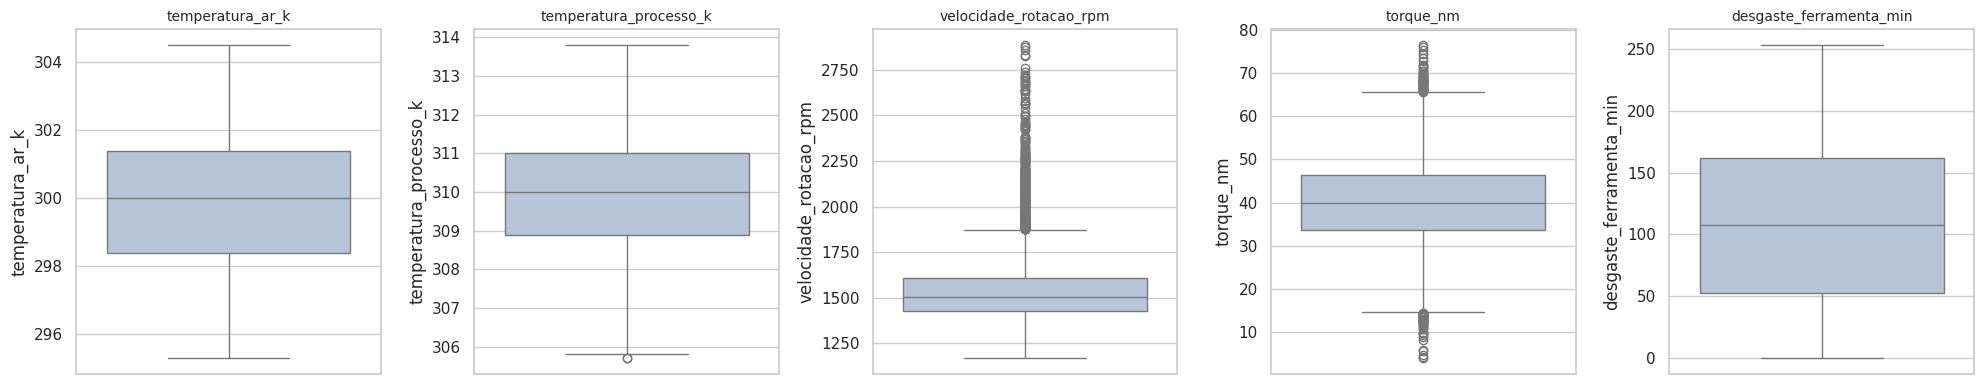

In [14]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, COLS_NUM):
    sns.boxplot(y=df[col], ax=ax, color="lightsteelblue")
    ax.set_title(col, fontsize=10)
plt.tight_layout()
plt.show()

In [15]:
taxa_geral = df["falha_maquina"].mean() * 100
linhas = []
for col in COLS_NUM:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (df[col] < lo) | (df[col] > hi)
    linhas.append({
        "variavel": col, "limite_inf": round(lo, 2), "limite_sup": round(hi, 2),
        "n_outliers": int(mask.sum()), "pct_outliers": round(mask.mean() * 100, 2),
        "taxa_falha_nos_outliers_%": round(df.loc[mask, "falha_maquina"].mean() * 100, 2) if mask.any() else np.nan,
    })
print(f"Taxa de falha geral: {taxa_geral:.2f}%")
pd.DataFrame(linhas)

Taxa de falha geral: 3.39%


,variavel,limite_inf,limite_sup,n_outliers,pct_outliers,taxa_falha_nos_outliers_%
0,temperatura_ar_k,293.90,305.90,0,0.00,NaN
1,temperatura_processo_k,305.75,314.15,2,0.02,0.00
2,velocidade_rotacao_rpm,1158.50,1874.50,465,4.65,7.31
3,torque_nm,14.40,65.60,102,1.02,70.59
4,desgaste_ferramenta_min,-110.50,325.50,0,0.00,NaN


Fase 3 — Feature Engineering

Criamos potencia = velocidade_rotacao_rpm × torque_nm. Em física, potência mecânica é proporcional ao produto torque × velocidade angular, e rpm é proporcional à velocidade angular. Logo o produto é uma medida proporcional à potência. Essa combinação captura uma interação que nenhuma coluna isolada expressa: um motor com torque alto e rotação alta trabalha sob esforço muito maior. Os nulos já foram tratados na Fase 2, então a nova coluna não deve ter NaN.

In [36]:
df["potencia"] = df["velocidade_rotacao_rpm"] * df["torque_nm"]

# Validações: sem NaN e sem valores infinitos
assert df["potencia"].notna().all(), "Há NaN na coluna potencia!"
assert np.isfinite(df["potencia"]).all(), "Há valores infinitos!"

print(df["potencia"].describe().round(1))
print("\nCorrelação com o alvo:")
print(df[["torque_nm", "velocidade_rotacao_rpm", "potencia", "falha_maquina"]].corr()["falha_maquina"].round(3))

count    10000.0
mean     59961.2
std       9951.1
min      10966.8
25%      53497.0
50%      60121.1
75%      66413.0
max      99980.4
Name: potencia, dtype: float64

Correlação com o alvo:
torque_nm                 0.184
velocidade_rotacao_rpm   -0.040
potencia                  0.169
falha_maquina             1.000
Name: falha_maquina, dtype: float64


Fase 4 — Divisão e Balanceamento dos Dados

In [17]:
mapa_tipo = {"L": 0, "M": 1, "H": 2}
df["tipo_cod"] = df["tipo"].map(mapa_tipo)
assert df["tipo_cod"].notna().all()

FEATURES = ["tipo_cod"] + COLS_NUM + ["potencia"]
X = df[FEATURES]
y = df["falha_maquina"]
print("Variáveis preditoras:", FEATURES)
print("X:", X.shape, "| y:", y.shape)

Variáveis preditoras: ['tipo_cod', 'temperatura_ar_k', 'temperatura_processo_k', 'velocidade_rotacao_rpm', 'torque_nm', 'desgaste_ferramenta_min', 'potencia']
X: (10000, 7) | y: (10000,)


In [18]:
# Divisão 80/20 estratificada: mantém a proporção de falhas igual em treino e teste

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
print(f"Treino: {X_train.shape[0]} linhas | Teste: {X_test.shape[0]} linhas")
print(f"% de falhas -> original: {y.mean()*100:.2f} | treino: {y_train.mean()*100:.2f} | teste: {y_test.mean()*100:.2f}")

Treino: 8000 linhas | Teste: 2000 linhas
% de falhas -> original: 3.39 | treino: 3.39 | teste: 3.40


O SMOTE cria exemplos sintéticos da classe minoritária interpolando entre vizinhos reais. Usamos a variante SMOTENC, que é o SMOTE preparado para colunas categóricas: como tipo_cod é categórica (0, 1, 2), ela não pode virar algo como 0,43. Escolhemos SMOTE em vez de Random Under Sampling porque undersampling descartaria cerca de 95% dos dados da classe majoritária, e perderíamos muita informação.

In [19]:
idx_categ = [FEATURES.index("tipo_cod")]   # posição da coluna categórica
smote = SMOTENC(categorical_features=idx_categ, random_state=SEED)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)   # SÓ no treino

print("Treino ANTES  :", y_train.value_counts().to_dict())
print("Treino DEPOIS :", y_train_bal.value_counts().to_dict())
print("Teste (intocado):", y_test.value_counts().to_dict())

Treino ANTES  : {0: 7729, 1: 271}
Treino DEPOIS : {0: 7729, 1: 7729}
Teste (intocado): {0: 1932, 1: 68}


Fase 5 — Escalonamento (StandardScaler)

In [20]:
COLS_CONT = COLS_NUM + ["potencia"]

scaler = StandardScaler()
X_train_knn = X_train_bal.copy()
X_test_knn = X_test.copy()
X_train_knn[COLS_CONT] = scaler.fit_transform(X_train_bal[COLS_CONT])   # aprende e aplica
X_test_knn[COLS_CONT] = scaler.transform(X_test[COLS_CONT])             # apenas aplica

# Árvore: dados ORIGINAIS, sem escalonamento
X_train_tree, X_test_tree = X_train_bal, X_test

print("Média/desvio do treino escalonado (esperado ~0 e ~1):")
display(X_train_knn[COLS_CONT].agg(["mean", "std"]).round(3))

Média/desvio do treino escalonado (esperado ~0 e ~1):


,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,potencia
mean,-0.0,-0.0,-0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0


Fase 6 — Ajuste de Parâmetros e Combate ao Overfitting

In [21]:
resultados_knn = []
for k in [1, 3, 5, 7, 11, 15, 21]:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_knn, y_train_bal)
    acc_tr = accuracy_score(y_train_bal, knn.predict(X_train_knn))
    acc_te = accuracy_score(y_test, knn.predict(X_test_knn))
    resultados_knn.append({"K": k, "acuracia_treino": acc_tr, "acuracia_teste": acc_te, "gap": acc_tr - acc_te})

res_knn = pd.DataFrame(resultados_knn)
res_knn.round(4)

,K,acuracia_treino,acuracia_teste,gap
0,1,0.9867,0.9140,0.0727
1,3,0.9615,0.9070,0.0545
2,5,0.9533,0.8970,0.0563
3,7,0.9456,0.8940,0.0516
4,11,0.9366,0.8850,0.0516
5,15,0.9310,0.8845,0.0465
6,21,0.9259,0.8800,0.0459


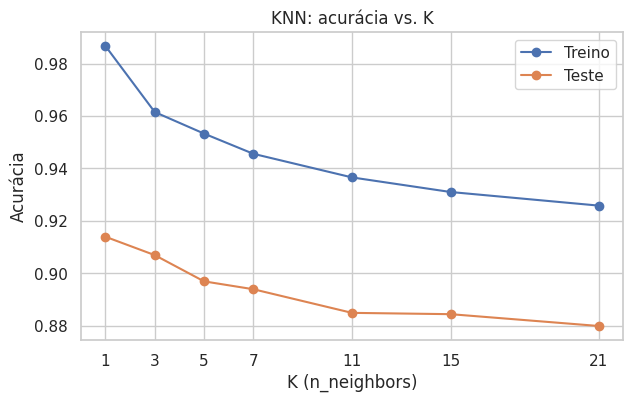

In [22]:
plt.figure(figsize=(7, 4))
plt.plot(res_knn["K"], res_knn["acuracia_treino"], marker="o", label="Treino")
plt.plot(res_knn["K"], res_knn["acuracia_teste"], marker="o", label="Teste")
plt.xlabel("K (n_neighbors)"); plt.ylabel("Acurácia"); plt.title("KNN: acurácia vs. K")
plt.xticks(res_knn["K"]); plt.legend(); plt.show()

In [23]:
resultados_arv = []
for prof in [2, 3, 5, 7, 10, None]:
    arv = DecisionTreeClassifier(max_depth=prof, random_state=SEED)
    arv.fit(X_train_tree, y_train_bal)
    acc_tr = accuracy_score(y_train_bal, arv.predict(X_train_tree))
    acc_te = accuracy_score(y_test, arv.predict(X_test_tree))
    resultados_arv.append({"max_depth": prof, "acuracia_treino": acc_tr, "acuracia_teste": acc_te, "gap": acc_tr - acc_te})

res_arv = pd.DataFrame(resultados_arv)
res_arv.round(4)

,max_depth,acuracia_treino,acuracia_teste,gap
0,2.0,0.8060,0.9065,-0.1005
1,3.0,0.8602,0.8595,0.0007
2,5.0,0.9030,0.9060,-0.0030
3,7.0,0.9154,0.9255,-0.0101
4,10.0,0.9444,0.9150,0.0294
5,NaN,0.9926,0.9295,0.0631


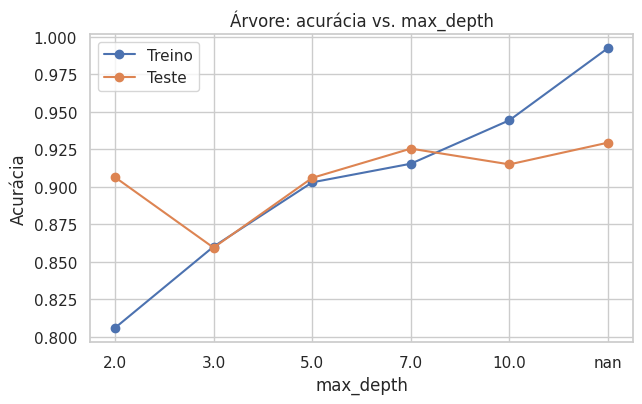

In [24]:
rotulos = [str(p) for p in res_arv["max_depth"]]
plt.figure(figsize=(7, 4))
plt.plot(rotulos, res_arv["acuracia_treino"], marker="o", label="Treino")
plt.plot(rotulos, res_arv["acuracia_teste"], marker="o", label="Teste")
plt.xlabel("max_depth"); plt.ylabel("Acurácia"); plt.title("Árvore: acurácia vs. max_depth")
plt.legend(); plt.show()

Diagnóstico de overfitting

KNN. O overfitting aparece em K = 1: acurácia de treino de 98,65% contra 91,35% no teste, o maior gap (7,3 p.p.). Com K = 1 o modelo "decora" cada ponto (inclusive os sintéticos do SMOTE e o ruído). À medida que K cresce, o gap diminui (4,6 p.p. em K = 21), mas a acurácia de teste também cai (de 91,4% para 88,0%): fronteiras muito suavizadas passam a errar mais. Não existe um K que melhore o teste e reduza o gap ao mesmo tempo, e K = 15 é um bom compromisso (gap de 4,7 p.p., teste de 88,45%).

Árvore. O overfitting aparece com max_depth=None: treino de 99,26% e teste de 92,85% (gap de 6,4 p.p.), porque a árvore cresce até memorizar o treino. Com max_depth=10 o gap cai para 2,9 p.p.; com max_depth=7 o treino (91,54%) e o teste (92,55%) praticamente se igualam (gap ≈ −1 p.p.), ou seja, estabilidade, e a perda de teste em relação ao máximo é de apenas 0,3 p.p. (6 registros em 2.000). Profundidades 2 e 3 mostram underfitting (acurácia de treino de apenas 80,6% e 86,0%: o modelo é simples demais).

Fase 7 — Avaliação Final e Veredito

In [25]:
LIMITE_GAP = 0.05

def escolher(res, coluna):
    ordem = res.sort_values(["acuracia_teste", "gap"], ascending=[False, True])
    bruta = ordem.iloc[0]
    estavel = ordem[ordem["gap"] <= LIMITE_GAP].iloc[0]
    conv = lambda v: None if pd.isna(v) else int(v)
    return conv(bruta[coluna]), conv(estavel[coluna])

k_bruto, k_estavel = escolher(res_knn, "K")
d_bruto, d_estavel = escolher(res_arv, "max_depth")

def treina_knn(k):
    return KNeighborsClassifier(n_neighbors=k).fit(X_train_knn, y_train_bal)

def treina_arv(d):
    return DecisionTreeClassifier(max_depth=d, random_state=SEED).fit(X_train_tree, y_train_bal)

modelos = {
    "KNN (A: maior acurácia)":      (treina_knn(k_bruto),    X_test_knn,  f"K={k_bruto}"),
    "KNN (B: estável)":             (treina_knn(k_estavel),  X_test_knn,  f"K={k_estavel}"),
    "Árvore (A: maior acurácia)":   (treina_arv(d_bruto),    X_test_tree, f"max_depth={d_bruto}"),
    "Árvore (B: estável)":          (treina_arv(d_estavel),  X_test_tree, f"max_depth={d_estavel}"),
}

acc_base = (y_test == 0).mean()   # baseline: sempre prever 0
linhas = []
preds = {}
for nome, (modelo, Xt, param) in modelos.items():
    p = modelo.predict(Xt)
    preds[nome] = p
    rep = classification_report(y_test, p, output_dict=True, zero_division=0)
    linhas.append({"modelo": nome, "parametro": param,
                   "acuracia_teste": accuracy_score(y_test, p),
                   "recall_falha": rep["1"]["recall"], "precisao_falha": rep["1"]["precision"],
                   "f1_falha": rep["1"]["f1-score"]})
linhas.append({"modelo": "Baseline (sempre 'sem falha')", "parametro": "-", "acuracia_teste": acc_base,
               "recall_falha": 0.0, "precisao_falha": 0.0, "f1_falha": 0.0})
tabela_final = pd.DataFrame(linhas)
tabela_final.round(4)

,modelo,parametro,acuracia_teste,recall_falha,precisao_falha,f1_falha
0,KNN (A: maior acurácia),K=1,0.9140,0.5588,0.2111,0.3065
1,KNN (B: estável),K=15,0.8845,0.6471,0.1753,0.2759
2,Árvore (A: maior acurácia),max_depth=None,0.9295,0.6618,0.2761,0.3896
3,Árvore (B: estável),max_depth=7,0.9255,0.6176,0.2545,0.3605
4,Baseline (sempre 'sem falha'),-,0.9660,0.0000,0.0000,0.0000


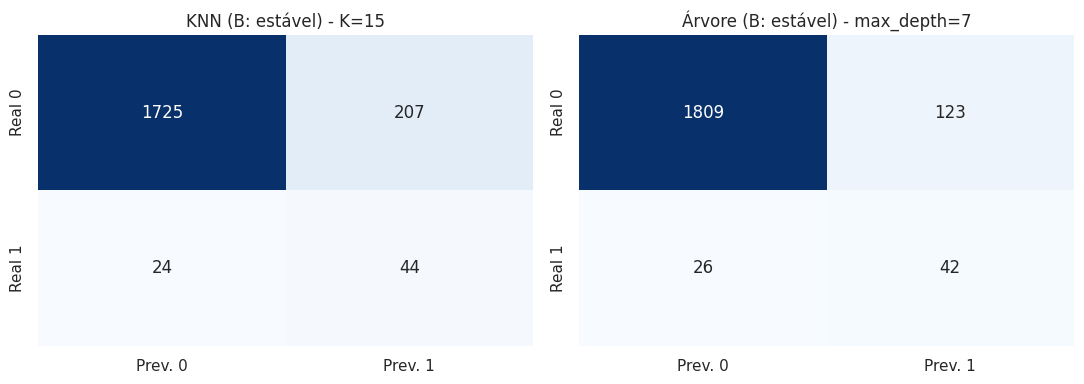

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, nome in zip(axes, ["KNN (B: estável)", "Árvore (B: estável)"]):
    sns.heatmap(confusion_matrix(y_test, preds[nome]), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Prev. 0", "Prev. 1"], yticklabels=["Real 0", "Real 1"])
    ax.set_title(f"{nome} - {modelos[nome][2]}")
plt.tight_layout(); plt.show()

In [27]:
acc = tabela_final.set_index("modelo")["acuracia_teste"]
print("=== Acurácia no teste ===")
print(f"KNN    (A) {acc['KNN (A: maior acurácia)']:.4f} | (B) {acc['KNN (B: estável)']:.4f}")
print(f"Árvore (A) {acc['Árvore (A: maior acurácia)']:.4f} | (B) {acc['Árvore (B: estável)']:.4f}")

for criterio, kn, ar in [("A", "KNN (A: maior acurácia)", "Árvore (A: maior acurácia)"),
                         ("B", "KNN (B: estável)", "Árvore (B: estável)")]:
    v = "Árvore de Decisão" if acc[ar] > acc[kn] else ("KNN" if acc[kn] > acc[ar] else "Empate")
    print(f"Critério {criterio}: vence {v} (diferença de {abs(acc[ar]-acc[kn])*100:.2f} p.p.)")

=== Acurácia no teste ===
KNN    (A) 0.9140 | (B) 0.8845
Árvore (A) 0.9295 | (B) 0.9255
Critério A: vence Árvore de Decisão (diferença de 1.55 p.p.)
Critério B: vence Árvore de Decisão (diferença de 4.10 p.p.)


Conclusão e recomendação

Veredito: a Árvore de Decisão supera o KNN em ambos os critérios (por 1,5 p.p. no critério bruto e por 4,1 p.p. no critério de estabilidade). Recomendação: Árvore de Decisão com max_depth=7. Ela é praticamente tão precisa quanto a árvore sem limite (diferença de 0,3 p.p.), porém sem sinais de overfitting, o que é mais confiável para dados futuros. Além disso, é interpretável (a Engenharia pode ver as regras) e dispensa escalonamento.